In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df_house = pd.read_csv("cleandataset.csv")
df_house.head()

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view_quality,condition,grade,...,lat,long,sqft_living15,sqft_lot15,date,price,basement_was_missing,view_was_missing,is_renovated,renovated_was_missing
0,7129300520,3.0,1.00,1180.0,5650.0,1.0,0,0.0,3,7,...,47.5112,-122.257,1340.0,5650.0,2014-10-13,221900.0,0,0,0,0
1,6414100192,3.0,2.25,2570.0,7242.0,2.0,0,0.0,3,7,...,47.7210,-122.319,1690.0,7639.0,2014-12-09,538000.0,0,0,1,0
2,5631500400,2.0,1.00,770.0,10000.0,1.0,0,0.0,3,6,...,47.7379,-122.233,2720.0,8062.0,2015-02-25,180000.0,0,0,0,0
3,2487200875,4.0,3.00,1960.0,5000.0,1.0,0,0.0,5,7,...,47.5208,-122.393,1360.0,5000.0,2014-12-09,604000.0,0,0,0,0
4,1954400510,3.0,2.00,1680.0,8080.0,1.0,0,0.0,3,8,...,47.6168,-122.045,1800.0,7503.0,2015-02-18,510000.0,0,0,0,0


In [3]:
df_house.describe()

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view_quality,condition,grade,...,zipcode,lat,long,sqft_living15,sqft_lot15,price,basement_was_missing,view_was_missing,is_renovated,renovated_was_missing
count,2.155000e+04,21550.000000,21550.000000,21550.000000,21550.000000,21550.000000,21550.000000,21550.000000,21550.000000,21550.000000,...,21550.000000,21550.000000,21550.000000,21550.000000,21550.000000,2.155000e+04,21550.0,21550.000000,21550.000000,21550.0
mean,4.582919e+09,3.369698,2.111705,2072.310534,14477.167053,1.493341,0.006636,0.230209,3.410302,7.651183,...,98078.035824,47.560096,-122.214279,1982.073271,12530.318051,5.367718e+05,0.0,0.002923,0.034339,0.0
std,2.876470e+09,0.902701,0.760922,894.081631,33683.145021,0.539596,0.081191,0.759213,0.650701,1.162330,...,53.509654,0.138575,0.140524,675.099766,25187.144329,3.504974e+05,0.0,0.053991,0.182102,0.0
min,1.000102e+06,1.000000,0.500000,370.000000,520.000000,1.000000,0.000000,0.000000,1.000000,3.000000,...,98001.000000,47.155900,-122.519000,399.000000,651.000000,7.800000e+04,0.0,0.000000,0.000000,0.0
25%,2.123212e+09,3.000000,1.750000,1420.000000,5040.000000,1.000000,0.000000,0.000000,3.000000,7.000000,...,98033.000000,47.470925,-122.328000,1490.000000,5100.000000,3.210068e+05,0.0,0.000000,0.000000,0.0
50%,3.904961e+09,3.000000,2.250000,1910.000000,7605.500000,1.500000,0.000000,0.000000,3.000000,7.000000,...,98065.000000,47.571900,-122.231000,1840.000000,7620.000000,4.500000e+05,0.0,0.000000,0.000000,0.0
75%,7.312200e+09,4.000000,2.500000,2549.250000,10630.750000,2.000000,0.000000,0.000000,4.000000,8.000000,...,98118.000000,47.678100,-122.125000,2360.000000,10063.750000,6.411500e+05,0.0,0.000000,0.000000,0.0
max,9.900000e+09,11.000000,7.500000,8000.000000,641203.000000,3.500000,1.000000,4.000000,5.000000,13.000000,...,98199.000000,47.777600,-121.315000,5000.000000,438213.000000,5.350000e+06,0.0,1.000000,1.000000,0.0


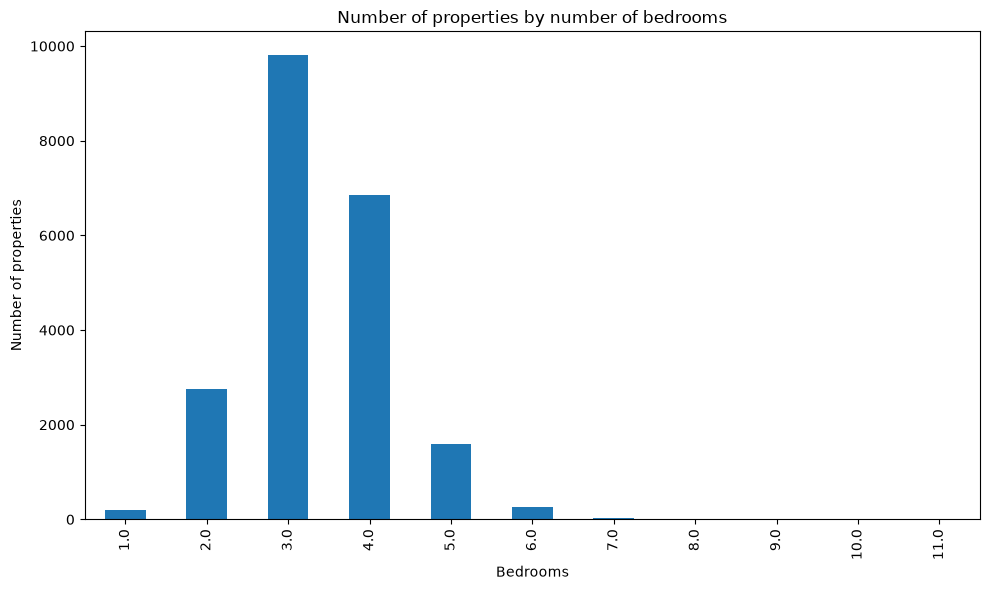

In [4]:
df_house["bedrooms"].value_counts().sort_index().plot(kind="bar", figsize=(10, 6))
plt.title("Number of properties by number of bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

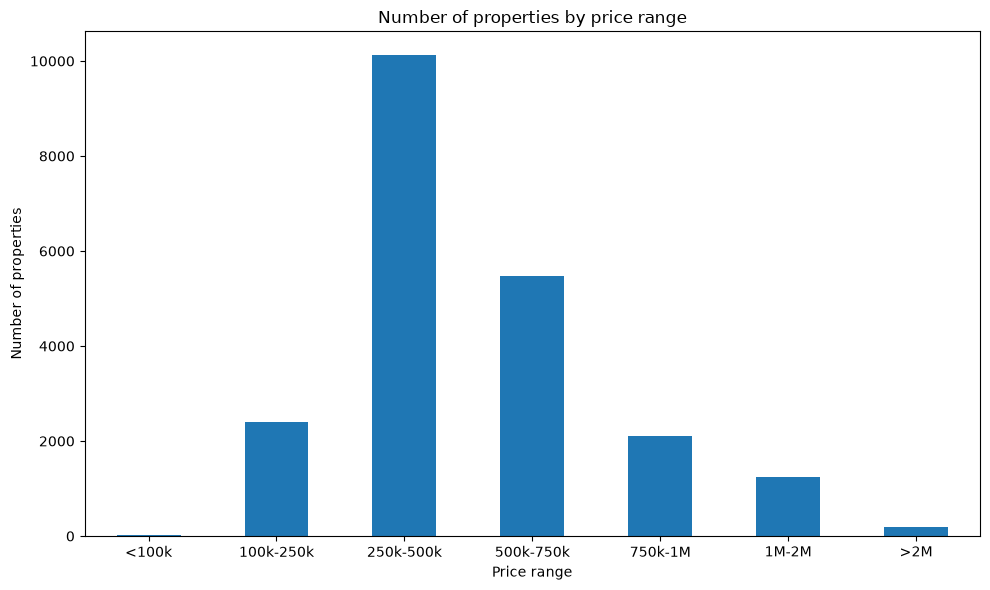

In [5]:
# Define price ranges
bins = [0,100_000, 250_000, 500_000, 750_000, 1_000_000, 2_000_000, df_house["price"].max()]
labels = ["<100k","100k-250k", "250k-500k", "500k-750k", "750k-1M", "1M-2M", ">2M"]

df_house["price_range"] = pd.cut(df_house["price"], bins=bins, labels=labels)

# Plot
df_house["price_range"].value_counts().sort_index().plot(kind="bar", figsize=(10, 6))
plt.title("Number of properties by price range")
plt.xlabel("Price range")
plt.ylabel("Number of properties")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

55 properties
zipcode
98001    7.25
98002    7.00
98003    7.25
98022    7.00
98023    7.17
98030    8.00
98031    7.00
98032    7.00
98042    7.00
98055    6.33
98056    5.00
98058    7.00
98059    7.00
98065    6.00
98106    6.00
98118    6.33
98146    6.40
98168    6.50
98178    6.33
98188    7.00
98198    6.80
Name: grade, dtype: float64


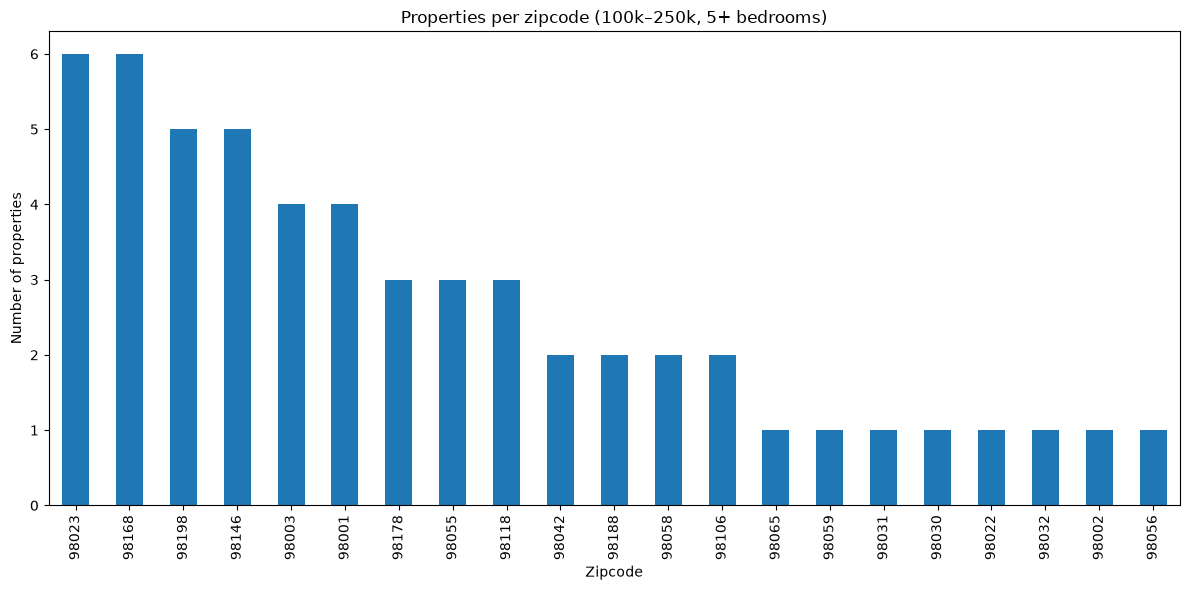

In [7]:



# 1. Filter: price between 100k and 250k, at least 5 bedrooms
df_filtered = df_house[
    (df_house["price"].between(100_000, 250_000)) &
    (df_house["bedrooms"] >= 5)
]
print(len(df_filtered), "properties")

# 2. Mean grade per zipcode
mean_grade = df_filtered.groupby("zipcode")["grade"].mean().round(2)
print(mean_grade)

# 3. Number of properties per zipcode
zip_counts = df_filtered["zipcode"].value_counts()

zip_counts.plot(kind="bar", figsize=(12, 6))
plt.title("Properties per zipcode (100k–250k, 5+ bedrooms)")
plt.xlabel("Zipcode")
plt.ylabel("Number of properties")
plt.xticks(rotation=90)
plt.tight_layout()
#plt.show()

In [14]:
import numpy as np

# 1. Median of log lot size per zipcode (robust against extreme lots)
zip_lot = (
    df_house.assign(log_lot15=np.log(df_house["sqft_lot15"]))
    .groupby("zipcode")["log_lot15"]
    .median()
)

# 2. Social score: smaller plots -> higher score (scaled 0-100)
social_score = 100 * (zip_lot.max() - zip_lot) / (zip_lot.max() - zip_lot.min())
social_score = social_score.round(1)

# 3. Add both fields to the data
df_house["zip_median_lot15"] = df_house["zipcode"].map(np.exp(zip_lot).round(0))
df_house["social_score"] = df_house["zipcode"].map(social_score)

# Check the result
print(df_house[["zipcode", "sqft_lot15", "zip_median_lot15", "social_score"]].head())

# Top 10 zipcodes by social score
print(social_score.sort_values(ascending=False).head(10))

   zipcode  sqft_lot15  zip_median_lot15  social_score
0    98178      5650.0            7200.0          68.1
1    98125      7639.0            7555.0          66.3
2    98028      8062.0            9994.0          55.6
3    98136      5000.0            5700.0          77.0
4    98074      7503.0           10045.0          55.4
zipcode
98102    100.0
98109     94.5
98119     94.5
98122     93.0
98103     92.0
98107     91.6
98144     90.5
98105     88.7
98112     86.0
98117     84.4
Name: log_lot15, dtype: float64


In [15]:
# Does the hypothesis hold? Grade distribution of 5+ bedroom houses, 100k-250k
print(df_filtered["grade"].value_counts().sort_index())

share_6_7 = df_filtered["grade"].between(6, 7).mean()
print(f"Share with grade 6-7: {share_6_7:.0%}")

# Which zipcodes have such houses?
match = df_filtered[df_filtered["grade"].between(6, 7)]
print(match.groupby("zipcode").agg(
    n=("price", "size"),
    median_price=("price", "median"),
    social_score=("zipcode", lambda z: social_score[z.iloc[0]])
).sort_values("social_score", ascending=False))

grade
5     2
6    14
7    35
8     4
Name: count, dtype: int64
Share with grade 6-7: 89%
         n  median_price  social_score
zipcode                               
98106    2      197500.0          81.4
98118    3      183750.0          79.2
98065    1      201000.0          75.7
98178    3      230000.0          68.1
98002    1      246000.0          67.5
98055    2      244000.0          66.7
98031    1      220000.0          65.2
98042    2      227500.0          64.3
98032    1      158550.0          63.7
98146    5      185000.0          63.6
98198    5      210000.0          63.4
98058    2      210662.5          62.7
98023    5      230000.0          62.5
98003    3      230000.0          61.4
98059    1      200000.0          60.7
98001    3      247000.0          59.9
98168    6      242475.0          59.2
98022    1      250000.0          58.4
98188    2      241000.0          58.0


| Proxy | Columns | Why it suggests a social neighborhood |
|---|---|---|
| Neighborhood stability | `sqft_living`, `sqft_living15` | Similar-sized homes suggest a coherent, family-oriented area |
| Housing age mix | `yr_built` | Newer subdivisions (1980s+) are often family-oriented |
| Condition and grade | `condition`, `grade` | Most homes in the area are in good shape |
| Location | `zipcode`, `lat`, `long` | Group by area to compare neighborhoods |

55 properties
         n_properties  mean_grade  median_price  social_score
zipcode                                                      
98106               2        6.00      197500.0          81.4
98118               3        6.33      183750.0          79.2
98065               1        6.00      201000.0          75.7
98178               3        6.33      230000.0          68.1
98002               1        7.00      246000.0          67.5
98030               1        8.00      248000.0          66.8
98055               3        6.33      238000.0          66.7
98056               1        5.00      190000.0          65.4
98031               1        7.00      220000.0          65.2
98042               2        7.00      227500.0          64.3


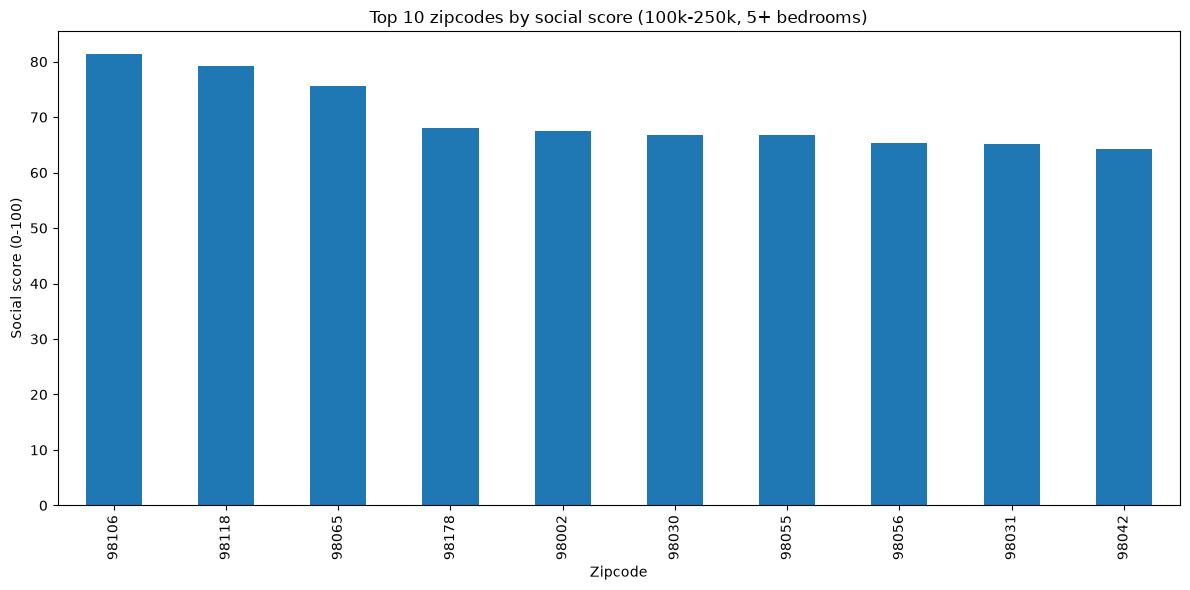

In [16]:
# 1. Filter: price between 100k and 250k, at least 5 bedrooms
df_filtered = df_house[
    (df_house["price"].between(100_000, 250_000)) &
    (df_house["bedrooms"] >= 5)
]
print(len(df_filtered), "properties")

# 2. Summary per zipcode: count, mean grade, median price, social score
summary = (
    df_filtered.groupby("zipcode")
    .agg(
        n_properties=("price", "size"),
        mean_grade=("grade", "mean"),
        median_price=("price", "median"),
    )
    .round(2)
)
summary["social_score"] = social_score.reindex(summary.index)

# 3. Top 10 zipcodes by social score (within the filtered data)
top10 = summary.sort_values("social_score", ascending=False).head(10)
print(top10)

# 4. Plot: social score for the filtered zipcodes
top10["social_score"].plot(kind="bar", figsize=(12, 6))
plt.title("Top 10 zipcodes by social score (100k-250k, 5+ bedrooms)")
plt.xlabel("Zipcode")
plt.ylabel("Social score (0-100)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

1394 properties
         n_properties  mean_grade  median_price  social_score
zipcode                                                      
98106              28        6.54      212500.0          81.4
98108              14        7.00      230000.0          80.3
98118              33        6.52      221000.0          79.2
98038              45        6.80      232000.0          70.7
98178              44        6.36      211000.0          68.1
98002              81        6.49      208000.0          67.5
98030              45        6.82      225205.0          66.8
98055              34        6.85      223000.0          66.7
98133               8        6.75      223000.0          66.2
98056              28        6.32      230000.0          65.4


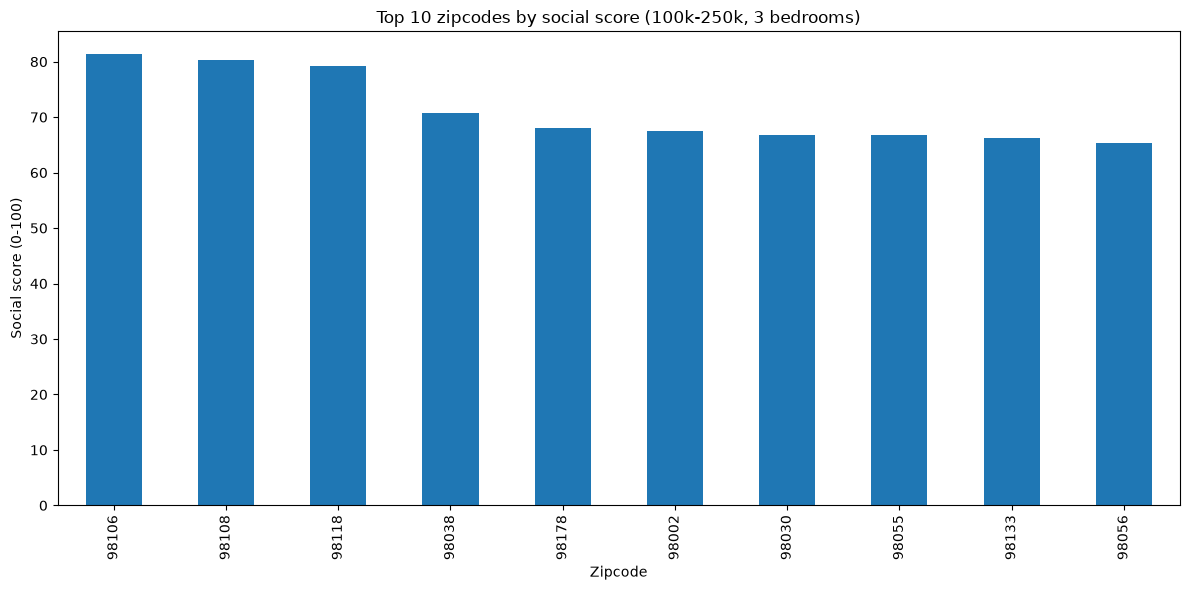

In [17]:
# 1. Filter: price between 100k and 250k, exactly 3 bedrooms
df_filtered_3 = df_house[
    (df_house["price"].between(100_000, 250_000)) &
    (df_house["bedrooms"] == 3)
]
print(len(df_filtered_3), "properties")

# 2. Summary per zipcode: count, mean grade, median price, social score
summary_3 = (
    df_filtered_3.groupby("zipcode")
    .agg(
        n_properties=("price", "size"),
        mean_grade=("grade", "mean"),
        median_price=("price", "median"),
    )
    .round(2)
)
summary_3["social_score"] = social_score.reindex(summary_3.index)

# 3. Top 10 zipcodes by social score (only zipcodes with at least 5 houses)
top10_3 = (
    summary_3[summary_3["n_properties"] >= 5]
    .sort_values("social_score", ascending=False)
    .head(10)
)
print(top10_3)

# 4. Plot: social score for the top 10 zipcodes
top10_3["social_score"].plot(kind="bar", figsize=(12, 6))
plt.title("Top 10 zipcodes by social score (100k-250k, 3 bedrooms)")
plt.xlabel("Zipcode")
plt.ylabel("Social score (0-100)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

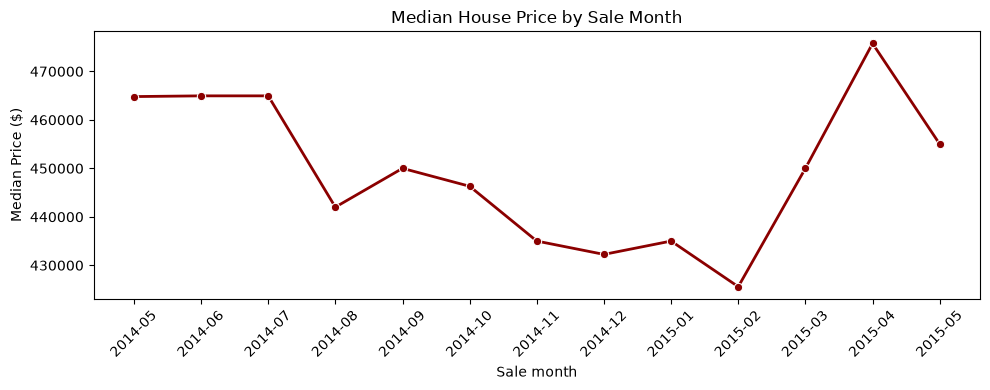

   sale_month  median_price  n_sales
0     2014-05      464800.0     1764
1     2014-06      464950.0     2172
2     2014-07      464950.0     2205
3     2014-08      442000.0     1935
4     2014-09      450000.0     1767
5     2014-10      446300.0     1872
6     2014-11      435000.0     1408
7     2014-12      432250.0     1468
8     2015-01      435000.0      971
9     2015-02      425590.0     1245
10    2015-03      450000.0     1873
11    2015-04      475750.0     2226
12    2015-05      455000.0      644


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sale month (year + month, so May 2014 and May 2015 stay separate)
df_house["date"] = pd.to_datetime(df_house["date"])
df_house["sale_month"] = df_house["date"].dt.to_period("M").astype(str)

# 2. Monthly median price and number of sales
monthly_price_summary = (
    df_house.groupby("sale_month")
    .agg(median_price=("price", "median"), n_sales=("price", "size"))
    .reset_index()
    .sort_values("sale_month")
)

# 3. Graph the monthly median price
plt.figure(figsize=(10, 4))
sns.lineplot(data=monthly_price_summary, x="sale_month", y="median_price",
             marker="o", color="darkred", linewidth=2)
plt.title("Median House Price by Sale Month")
plt.xlabel("Sale month")
plt.ylabel("Median Price ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(monthly_price_summary)

5 properties
zipcode
98023    6.0
98092    6.0
98146    6.0
Name: grade, dtype: float64


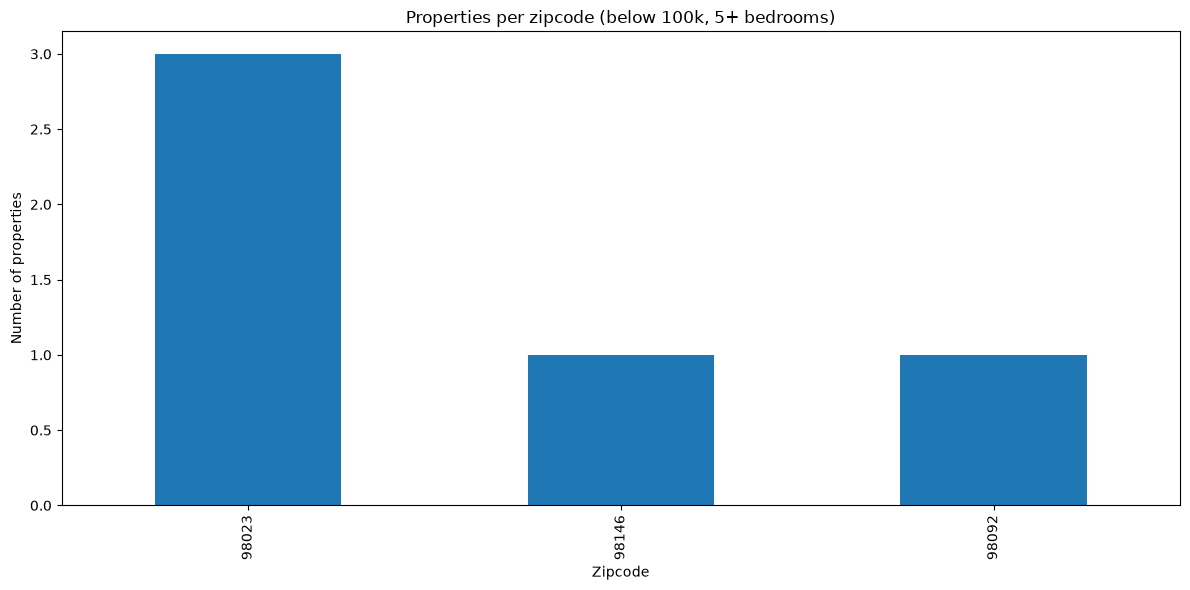

In [ ]:
# 1. Filter: price below 100k, at least 3 bedrooms
df_filtered = df_house[
    (df_house["price"] < 100_000) &
    (df_house["bedrooms"] >= 3)
]
print(len(df_filtered), "properties")

# 2. Mean grade per zipcode
mean_grade = df_filtered.groupby("zipcode")["grade"].mean().round(2)
print(mean_grade)

# 3. Number of properties per zipcode
zip_counts = df_filtered["zipcode"].value_counts()

zip_counts.plot(kind="bar", figsize=(12, 6))
plt.title("Properties per zipcode (below 100k, 5+ bedrooms)")
plt.xlabel("Zipcode")
plt.ylabel("Number of properties")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

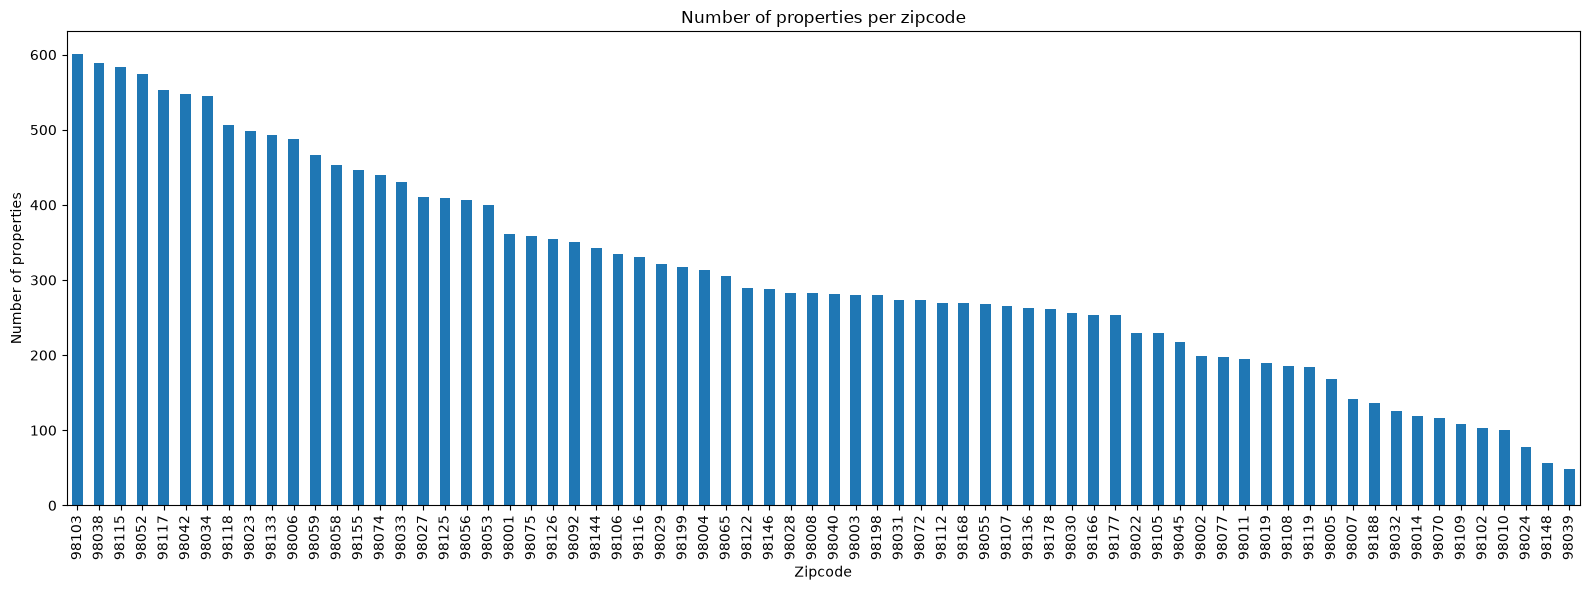

In [20]:


zip_counts = df_house["zipcode"].value_counts()

zip_counts.plot(kind="bar", figsize=(16, 6))
plt.title("Number of properties per zipcode")
plt.xlabel("Zipcode")
plt.ylabel("Number of properties")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [13]:
import plotly.express as px

zip_stats = (df_house.groupby("zipcode")
             .agg(n=("price", "size"),
                  median_price=("price", "median"),
                  lat=("lat", "mean"),
                  long=("long", "mean"))
             .reset_index())

fig = px.scatter_map(zip_stats, lat="lat", lon="long",
                     size="n", color="n",
                     hover_name="zipcode",
                     hover_data={"median_price": ":,.0f", "n": True,
                                 "lat": False, "long": False},
                     color_continuous_scale="Viridis",
                     zoom=8.5, height=700,
                     map_style="carto-positron")
fig.update_layout(title="Number of properties per zipcode")
fig.show()

bedrooms
3-4    455000.0
5-6    620000.0
Name: price, dtype: float64 
Change: 36%


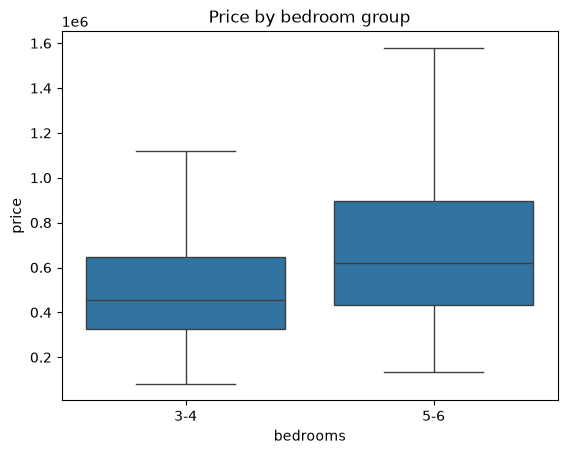

In [22]:
# H1: median price, 3-4 vs 5-6 bedrooms
grp = pd.cut(df_house["bedrooms"], bins=[2, 4, 6], labels=["3-4", "5-6"])
med = df_house.groupby(grp, observed=True)["price"].median()
print(med, "\nChange: {:.0%}".format(med["5-6"] / med["3-4"] - 1))
sns.boxplot(data=df_house[grp.notna()], x=grp[grp.notna()], y="price", showfliers=False)
plt.title("Price by bedroom group"); plt.show()



In [23]:
# H3: winter (Dec-Feb) vs peak (May-Jul)
m = df_house["date"].dt.month
winter = df_house.loc[m.isin([12, 1, 2]), "price"].median()
peak = df_house.loc[m.isin([5, 6, 7]), "price"].median()
print("Winter: {:,.0f} | Peak: {:,.0f} | Difference: {:.1%}".format(winter, peak, winter / peak - 1))

Winter: 430,000 | Peak: 463,828 | Difference: -7.3%
